In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from typing import Tuple, Optional, Dict, List
import random
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import warnings
warnings.filterwarnings("ignore")
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)

print(f"Using device: {device}")

Using device: mps


---
# 1) Data Loading

```
Input:  "25 january 2003"  →  Output: "2003-01-25"
Input:  "march 5, 1998"    →  Output: "1998-03-05"
Input:  "01/12/2020"       →  Output: "2020-01-12"
```

This task is ideal because:
- It's deterministic (one correct answer per input)
- It requires **reordering** (the model must learn to rearrange year, month, day)
- It requires **alignment** (attention patterns are interpretable)

In [ ]:
from datetime import datetime, timedelta

# Date format templates for input variety
INPUT_FORMATS = [
    "%d %B %Y",  # 25 January 2003
    "%B %d, %Y",  # January 25, 2003
    "%d/%m/%Y",  # 25/01/2003
    "%m/%d/%Y",  # 01/25/2003
    "%d %b %Y",  # 25 Jan 2003
    "%b %d, %Y",  # Jan 25, 2003
    "%Y/%m/%d",  # 2003/01/25
    "%d-%m-%Y",  # 25-01-2003
]

# Target format is always ISO 8601
OUTPUT_FORMAT = "%Y-%m-%d"


def generate_date_pairs(n: int = 10000) -> List[Tuple[str, str]]:
    """Generate (input_date_string, target_iso_string) pairs."""
    pairs = []
    start_date = datetime(1950, 1, 1)
    end_date = datetime(2030, 12, 31)
    total_days = (end_date - start_date).days

    for _ in range(n):
        # Random date
        date = start_date + timedelta(days=random.randint(0, total_days))

        # Random input format
        fmt = random.choice(INPUT_FORMATS)
        input_str = date.strftime(fmt).lower()

        # Standardized output
        output_str = date.strftime(OUTPUT_FORMAT)
        pairs.append((input_str, output_str))

    return pairs


pairs = generate_date_pairs(20000)
print("Sample date pairs:")
for inp, out in pairs[:8]:
    print(f"  '{inp}' → '{out}'")

Sample date pairs:
  '23/02/1967' → '1967-02-23'
  '1980/03/22' → '1980-03-22'
  '28 may 1985' → '1985-05-28'
  '09/24/1958' → '1958-09-24'
  '18/01/1980' → '1980-01-18'
  '21 may 2007' → '2007-05-21'
  'march 16, 1955' → '1955-03-16'
  'may 02, 1976' → '1976-05-02'


In [3]:
# Special tokens
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"

class CharVocab:
    """Character-level vocabulary with special tokens."""

    def __init__(self):
        self.char_to_idx = {PAD_TOKEN: 0, SOS_TOKEN: 1, EOS_TOKEN: 2}
        self.idx_to_char = {0: PAD_TOKEN, 1: SOS_TOKEN, 2: EOS_TOKEN}

    def build(self, texts: List[str]) -> "CharVocab":
        """Build vocabulary from all characters in texts."""
        chars = sorted(set(c for text in texts for c in text))
        for c in chars:
            if c not in self.char_to_idx:
                idx = len(self.char_to_idx)
                self.char_to_idx[c] = idx
                self.idx_to_char[idx] = c
        return self

    def encode(self, text: str, add_eos: bool = False) -> List[int]:
        indices = [self.char_to_idx[c] for c in text]
        if add_eos:
            indices.append(self.char_to_idx[EOS_TOKEN])
        return indices

    def decode(self, indices: List[int]) -> str:
        chars = []
        for idx in indices:
            c = self.idx_to_char[idx]
            if c == EOS_TOKEN:
                break
            if c not in (PAD_TOKEN, SOS_TOKEN):
                chars.append(c)
        return "".join(chars)

    def __len__(self) -> int:
        return len(self.char_to_idx)


# Build separate vocabularies for source and target
src_texts = [p[0] for p in pairs]
tgt_texts = [p[1] for p in pairs]

src_vocab = CharVocab().build(src_texts)
tgt_vocab = CharVocab().build(tgt_texts)

print(
    f"Source vocab size: {len(src_vocab)} — chars: {list(src_vocab.char_to_idx.keys())[3:]}"
)
print(
    f"Target vocab size: {len(tgt_vocab)} — chars: {list(tgt_vocab.char_to_idx.keys())[3:]}"
)

Source vocab size: 38 — chars: [' ', ',', '-', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'l', 'm', 'n', 'o', 'p', 'r', 's', 't', 'u', 'v', 'y']
Target vocab size: 14 — chars: ['-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [4]:
class DateDataset(Dataset):
    """Dataset for date format translation."""

    def __init__(
        self,
        pairs: List[Tuple[str, str]],
        src_vocab: CharVocab,
        tgt_vocab: CharVocab,
        max_src_len: int = 30,
        max_tgt_len: int = 12,
    ):
        self.src_data = []
        self.tgt_input = [] 
        self.tgt_output = []

        sos_idx = tgt_vocab.char_to_idx[SOS_TOKEN]

        for src, tgt in pairs:
            src_enc = src_vocab.encode(src)
            tgt_enc = tgt_vocab.encode(tgt, add_eos=True)

            # Pad source
            src_padded = src_enc + [0] * (max_src_len - len(src_enc))

            # Decoder input: <sos> + target chars (no EOS)
            dec_input = [sos_idx] + tgt_enc[:-1]
            dec_input_padded = dec_input + [0] * (max_tgt_len - len(dec_input))

            # Decoder output: target chars + <eos>
            dec_output_padded = tgt_enc + [0] * (max_tgt_len - len(tgt_enc))

            self.src_data.append(
                torch.tensor(src_padded[:max_src_len], dtype=torch.long)
            )
            self.tgt_input.append(
                torch.tensor(dec_input_padded[:max_tgt_len], dtype=torch.long)
            )
            self.tgt_output.append(
                torch.tensor(dec_output_padded[:max_tgt_len], dtype=torch.long)
            )

    def __len__(self) -> int:
        return len(self.src_data)

    def __getitem__(self, idx: int):
        return self.src_data[idx], self.tgt_input[idx], self.tgt_output[idx]

# "YYYY-MM-DD" + EOS = 11 chars
MAX_SRC_LEN = 25
MAX_TGT_LEN = 12  

# Split 80/20
split = int(0.8 * len(pairs))
train_ds = DateDataset(pairs[:split], src_vocab, tgt_vocab, MAX_SRC_LEN, MAX_TGT_LEN)
test_ds = DateDataset(pairs[split:], src_vocab, tgt_vocab, MAX_SRC_LEN, MAX_TGT_LEN)

BATCH_SIZE = 128
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE)

print(f"Train: {len(train_ds)}, Test: {len(test_ds)}")

# Verify one sample
s, ti, to = train_ds[0]
print(f"\nSource:         '{src_vocab.decode(s.tolist())}'")
print(f"Decoder input:  {[tgt_vocab.idx_to_char[i] for i in ti.tolist() if i != 0]}")
print(f"Decoder target: {[tgt_vocab.idx_to_char[i] for i in to.tolist() if i != 0]}")

Train: 16000, Test: 4000

Source:         '23/02/1967'
Decoder input:  ['<sos>', '1', '9', '6', '7', '-', '0', '2', '-', '2', '3']
Decoder target: ['1', '9', '6', '7', '-', '0', '2', '-', '2', '3', '<eos>']


---
# 2) Attention

<img src='https://miro.medium.com/1*BfwFEH4tgY-JwHxr-2D2KQ.png' width=800 >


Every variant below — and every variant in the Transformer chapter — is the same three steps:

1. **Score** each encoder state $h_i$ against the current decoder state $s$ → $e_{t,i}$
2. **Normalize** the scores with softmax → $\alpha_{t,i}$
3. **Blend** the encoder states → $c_t = \sum_i \alpha_{t,i} \, h_i$

Only step 1 differs between the two historical families:

| Variant | Score $e_{t,i}$ | Learned params | Decoder state used |
|---------|-----------------|----------------|--------------------|
| Bahdanau — *additive* (2014) | $v^\top \tanh(W_s s_{t-1} + W_h h_i)$ | $W_s, W_h, v$ | $s_{t-1}$, **before** the LSTM step |
| Luong — *general* (2015) | $s_t^\top W_a h_i$ | $W_a$ | $s_t$, **after** the LSTM step |
| Luong — *dot* (2015) | $s_t^\top h_i$ | none | $s_t$ |

Two genuinely independent differences hide in that table, and it is worth keeping them apart:

**1. The score function.** Additive pushes both vectors through a shared hidden layer and reads off
a scalar — expressive, but it is a small MLP evaluated for every (decoder step, encoder position)
pair. Multiplicative scoring is a single matrix product, which is the whole reason it survived:
`dot` scoring becomes $\text{softmax}\!\left(QK^\top/\sqrt{d_k}\right)V$ in the Transformer, while
the additive branch was abandoned. The scaling factor and the learned Q/K/V projections are the
only things the Transformer adds.

**2. When the context is computed.** Bahdanau attends *before* the recurrent step, using the
previous state $s_{t-1}$, and feeds the context into the LSTM as part of its input. Luong runs the
LSTM first to get $s_t$, then attends and merges the context into the *output* through an
attentional vector $\tilde{h}_t = \tanh(W_c[c_t; s_t])$. So Luong's context can never influence the
recurrent state — only the prediction.

These two axes are orthogonal: additive scoring with Luong-style timing is perfectly valid. They
travel together historically because each paper picked one combination.

## 2.1 Attention Module

**Sample I/O:**

| Tensor | Shape |
|--------|-------|
| `encoder_outputs` | `(batch_num, src_seq_len, encoder_dim)` |
| `decoder_hidden` | `(batch_num, decoder_dim)` |
| `attention_weights` | `(batch_num, src_seq_len)` |
| `context_vector` | `(batch_num, encoder_dim)` |

In [ ]:
class Attention(nn.Module):
    """
    Attention over encoder outputs, with a swappable score function.

    The three steps (score → softmax → weighted sum) are identical for every
    variant; only `_score` changes:

        additive (Bahdanau):  e_i = v^T tanh(W_s @ s + W_h @ h_i)
        general  (Luong):     e_i = s^T @ W_a @ h_i
        dot      (Luong):     e_i = s^T @ h_i        (needs encoder_dim == decoder_dim)
    """

    SCORES = ("additive", "general", "dot")

    def __init__(
        self,
        encoder_dim: int,
        decoder_dim: int,
        attention_dim: int = 64,
        score: str = "additive",
    ):
        super().__init__()
        self.score = score

        if score == "additive":
            # Project encoder states and the decoder state into a shared space
            # (batch_num, src_seq_len, encoder_dim) → (batch_num, src_seq_len, attention_dim)
            self.W_h = nn.Linear(encoder_dim, attention_dim, bias=False)

            # (batch_num, decoder_dim) → (batch_num, attention_dim)
            self.W_s = nn.Linear(decoder_dim, attention_dim, bias=False)

            # Collapse the shared space to one scalar per position
            # (batch_num, src_seq_len, attention_dim) → (batch_num, src_seq_len, 1)
            self.v = nn.Linear(attention_dim, 1, bias=False)

        elif score == "general":
            # Bilinear form: one matrix bridges decoder space to encoder space
            # (batch_num, decoder_dim) → (batch_num, encoder_dim)
            self.W_a = nn.Linear(decoder_dim, encoder_dim, bias=False)

        else:
            assert encoder_dim == decoder_dim, "dot scoring needs matching dimensions"

    def _score(
        self,
        encoder_outputs: torch.Tensor,
        decoder_hidden: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            encoder_outputs: (batch_num, src_seq_len, encoder_dim)
            decoder_hidden: (batch_num, decoder_dim)
        Returns:
            energy: (batch_num, src_seq_len) — one unnormalized score per position
        """

        if self.score == "additive":
            # Broadcast the decoder projection across every source position
            # Input: (batch_num, src_seq_len, encoder_dim) + (batch_num, decoder_dim)
            # Output: (batch_num, src_seq_len, attention_dim)
            hidden = torch.tanh(
                self.W_h(encoder_outputs) + self.W_s(decoder_hidden).unsqueeze(1)
            )
            # (batch_num, src_seq_len)
            return self.v(hidden).squeeze(-1)

        else:
            # Both multiplicative variants are a single batched matrix product;
            # (batch_num, decoder_dim) → (batch_num, encoder_dim)
            query = decoder_hidden if self.score == "dot" else self.W_a(decoder_hidden)

            # Input: (batch_num, src_seq_len, encoder_dim) @ (batch_num, encoder_dim, 1)
            # Output: (batch_num, src_seq_len)
            return torch.bmm(encoder_outputs, query.unsqueeze(-1)).squeeze(-1)

    def forward(
        self,
        encoder_outputs: torch.Tensor,
        decoder_hidden: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Args:
            encoder_outputs: (batch_num, src_seq_len, encoder_dim)
            decoder_hidden: (batch_num, decoder_dim)
        Returns:
            context: (batch_num, encoder_dim)
            weights: (batch_num, src_seq_len)
        """
        # (batch_num, src_seq_len)
        energy = self._score(encoder_outputs, decoder_hidden)
        weights = F.softmax(energy, dim=1)

        # Weighted sum of encoder states
        # (batch_num, 1, src_seq_len) @ (batch_num, src_seq_len, encoder_dim)
        # → (batch_num, encoder_dim)
        context = torch.bmm(weights.unsqueeze(1), encoder_outputs).squeeze(1)

        return context, weights

In [ ]:
# Same shapes out of every variant —
# (batch_num, src_seq_len, encoder_dim) and (batch_num, decoder_dim)
enc_out = torch.randn(4, 20, 64)
dec_h = torch.randn(4, 64)

for score in Attention.SCORES:
    attn = Attention(encoder_dim=64, decoder_dim=64, attention_dim=32, score=score)
    ctx, wts = attn(enc_out, dec_h)
    n_params = sum(p.numel() for p in attn.parameters())
    print(
        f"{score:9} context={tuple(ctx.shape)}  weights={tuple(wts.shape)}  "
        f"sum={wts[0].sum():.4f}  params={n_params:,}"
    )

additive  context=(4, 64)  weights=(4, 20)  sum=1.0000  params=4,128
general   context=(4, 64)  weights=(4, 20)  sum=1.0000  params=4,096
dot       context=(4, 64)  weights=(4, 20)  sum=1.0000  params=0


## 2.2 Encoder - Decoder

1. In Bahdanau the context is part of the LSTM's *input*, so it shapes the recurrent
state that all later timesteps inherit. 
2. In Luong the context only touches the *output* projection,
leaving the recurrent state untouched. 
3. Luong is the cheaper and more modular of the two — and the
one the Transformer's decoder resembles, where attention is a separate sublayer applied to the
already-computed hidden state.

In [ ]:
class Encoder(nn.Module):
    """Bidirectional LSTM encoder."""

    def __init__(
        self, vocab_size: int, embed_dim: int, hidden_dim: int, dropout: float = 0.1
    ):
        super().__init__()
        # (batch_num, src_seq_len) → (batch_num, src_seq_len, embed_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Bidirectional: output dim is 2 * hidden_dim
        # (batch_num, src_seq_len, embed_dim) → (batch_num, src_seq_len, hidden_dim * 2)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)

        # Project bidirectional output to hidden_dim for decoder compatibility
        # (batch_num, src_seq_len, hidden_dim * 2) → (batch_num, src_seq_len, hidden_dim)
        self.fc = nn.Linear(hidden_dim * 2, hidden_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(
        self, src: torch.Tensor
    ) -> Tuple[torch.Tensor, Tuple[torch.Tensor, torch.Tensor]]:
        """
        Args:
            src: (batch_num, src_seq_len)
        Returns:
            outputs: (batch_num, src_seq_len, hidden_dim)
            (h_n, c_n): each (1, batch_num, hidden_dim) — for decoder init
        """
        # (batch_num, src_seq_len, embed_dim)
        embedded = self.dropout(self.embedding(src))

        # (batch_num, src_seq_len, hidden_dim * 2)
        # 2 final state for h_n and c_n (bidirectional)
        outputs, (h_n, c_n) = self.lstm(embedded)

        # Project to decoder dimension
        # (batch_num, src_seq_len, hidden_dim)
        outputs = torch.tanh(self.fc(outputs))

        # Combine bidirectional hidden states for decoder initialization
        # h_n: (1, batch_num, hidden_dim)
        h_n = torch.tanh(self.fc(torch.cat([h_n[0], h_n[1]], dim=1))).unsqueeze(0)
        c_n = torch.tanh(self.fc(torch.cat([c_n[0], c_n[1]], dim=1))).unsqueeze(0)

        return outputs, (h_n, c_n)

### Bahdanau vs. Luong

| Aspect | Bahdanau (2014) | Luong (2015) |
|--------|-----------------|--------------|
| Score | $v^\top\tanh(W_s s + W_h h_i)$ — additive | $s^\top W_a h_i$ — multiplicative |
| Cost per (t, i) pair | a small MLP | one matrix product |
| Decoder state used | $s_{t-1}$, before the recurrent step | $s_t$, after it |
| Context enters via | the LSTM **input** | the output projection |
| Parameters | more (three matrices) | fewer (one, or none for `dot`) |

Neither wins decisively on a task this small — but the multiplicative branch is the one that
scaled, because a matmul parallelizes and a per-pair MLP does not.


In [ ]:
class AttentionDecoder(nn.Module):
    """
    LSTM decoder that supports both attention wirings.

    style="bahdanau": attend with s_{t-1}, feed the context into the LSTM
    style="luong":    run the LSTM first, attend with s_t, merge into the output
    """

    STYLES = ("bahdanau", "luong")

    def __init__(
        self,
        vocab_size: int,
        embed_dim: int,
        hidden_dim: int,
        attention_dim: int,
        score: str = "additive",
        style: str = "bahdanau",
        dropout: float = 0.1,
    ):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.style = style

        # (batch_num,) → (batch_num, embed_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.attention = Attention(hidden_dim, hidden_dim, attention_dim, score=score)
        self.dropout = nn.Dropout(dropout)

        if style == "bahdanau":
            # LSTM consumes [target embedding + encoder context]
            # (batch_num, 1, embed_dim + hidden_dim) → (batch_num, 1, hidden_dim)
            self.lstm = nn.LSTM(embed_dim + hidden_dim, hidden_dim, batch_first=True)

            # Classifier sees the state, the context and the input embedding
            # (batch_num, hidden_dim * 2 + embed_dim) → (batch_num, vocab_size)
            self.fc = nn.Linear(hidden_dim * 2 + embed_dim, vocab_size)

        else:
            # LSTM consumes the embedding alone — no context yet
            # (batch_num, 1, embed_dim) → (batch_num, 1, hidden_dim)
            self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)

            # (batch_num, hidden_dim * 2) → (batch_num, hidden_dim)
            self.W_c = nn.Linear(hidden_dim * 2, hidden_dim, bias=False)

            # (batch_num, hidden_dim) → (batch_num, vocab_size)
            self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward_step(
        self,
        input_token: torch.Tensor,
        hidden: Tuple[torch.Tensor, torch.Tensor],
        encoder_outputs: torch.Tensor,
    ) -> Tuple[torch.Tensor, Tuple[torch.Tensor, torch.Tensor], torch.Tensor]:
        """
        Single decoder timestep.

        Args:
            input_token: (batch_num,) — current input token index
            hidden: (h, c) each (1, batch_num, hidden_dim)
            encoder_outputs: (batch_num, src_seq_len, hidden_dim)
        Returns:
            prediction: (batch_num, vocab_size)
            hidden: updated (h, c)
            attn_weights: (batch_num, src_seq_len)
        """
        # (batch_num,) → (batch_num, embed_dim)
        embedded = self.dropout(self.embedding(input_token))

        if self.style == "bahdanau":
            # Attend with the state carried in from the previous decoder step
            # Output: (batch_num, hidden_dim), (batch_num, src_seq_len)
            context, attn_weights = self.attention(
                encoder_outputs, hidden[0].squeeze(0)
            )

            # The context is part of the LSTM input, so it enters the recurrent state
            # (batch_num, 1, embed_dim + hidden_dim)
            lstm_out, hidden = self.lstm(
                torch.cat([embedded, context], dim=1).unsqueeze(1), hidden
            )

            # Skip-connection style classifier input
            # (batch_num, hidden_dim * 2 + embed_dim)
            combined = torch.cat([lstm_out.squeeze(1), context, embedded], dim=1)
        else:
            # (batch_num, 1, hidden_dim)
            lstm_out, hidden = self.lstm(embedded.unsqueeze(1), hidden)

            # Attend with the state we just produced
            # Output: (batch_num, hidden_dim), (batch_num, src_seq_len)
            context, attn_weights = self.attention(
                encoder_outputs, lstm_out.squeeze(1)
            )

            # Attentional vector merges context into the output path only
            # (batch_num, hidden_dim)
            combined = torch.tanh(
                self.W_c(torch.cat([context, lstm_out.squeeze(1)], dim=1))
            )

        # (batch_num, vocab_size)
        prediction = self.fc(self.dropout(combined))

        return prediction, hidden, attn_weights

In [ ]:
class Seq2SeqAttention(nn.Module):
    """
    Full sequence-to-sequence model, agnostic to the attention variant.

    Nothing here refers to a score function or a wiring style — it only calls
    `decoder.forward_step`, so the same loop drives Bahdanau and Luong alike.

    Supports teacher forcing during training:
      - With probability `teacher_forcing_ratio`, feed ground-truth token as next input
      - Otherwise, feed the model's own prediction (autoregressive)
    """

    def __init__(self, encoder: Encoder, decoder: AttentionDecoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(
        self,
        src: torch.Tensor,
        tgt_input: torch.Tensor,
        teacher_forcing_ratio: float = 0.5,
    ) -> Tuple[torch.Tensor, torch.Tensor]:
        """
        Args:
            src: (batch_num, src_seq_len)
            tgt_input: (batch_num, tgt_seq_len) — starts with <sos>
            teacher_forcing_ratio: probability of using ground-truth input
        Returns:
            outputs: (batch_num, tgt_seq_len, tgt_vocab_size)
            attention_weights: (batch_num, tgt_seq_len, src_seq_len)
        """
        batch_num = src.size(0)
        tgt_seq_len = tgt_input.size(1)
        tgt_vocab_size = self.decoder.fc.out_features
        src_seq_len = src.size(1)

        # encoder_outputs: (batch_num, src_seq_len, hidden_dim)
        encoder_outputs, hidden = self.encoder(src)

        # Storage for decoder outputs and attention
        all_outputs = torch.zeros(
            batch_num, tgt_seq_len, tgt_vocab_size, device=src.device
        )
        all_attention = torch.zeros(
            batch_num, tgt_seq_len, src_seq_len, device=src.device
        )

        # First decoder input is <sos>
        # (batch_num,)
        current_input = tgt_input[:, 0]

        for t in range(tgt_seq_len):
            # One decoder step
            prediction, hidden, attn_weights = self.decoder.forward_step(
                current_input, hidden, encoder_outputs
            )

            all_outputs[:, t] = prediction
            all_attention[:, t] = attn_weights

            # Teacher forcing: use ground truth or model's prediction
            use_teacher = random.random() < teacher_forcing_ratio
            if use_teacher and t + 1 < tgt_seq_len:
                current_input = tgt_input[:, t + 1]
            else:
                current_input = prediction.argmax(dim=1)

        return all_outputs, all_attention

## 2.3 Training Loop

In [9]:
# Hyperparameters — shared by both variants so the comparison is fair
EMBED_DIM = 32
HIDDEN_DIM = 128
ATTENTION_DIM = 64
DROPOUT = 0.1
LR = 1e-3
NUM_EPOCHS = 15
CLIP_NORM = 1.0


def compute_accuracy(outputs: torch.Tensor, targets: torch.Tensor) -> float:
    """
    Full-sequence accuracy (the entire date must match).

    Args:
        outputs: (batch_num, tgt_seq_len, vocab_size)
        targets: (batch_num, tgt_seq_len)
    """
    # (batch_num, tgt_seq_len)
    preds = outputs.argmax(dim=-1)

    # Mask padding positions
    mask = targets != 0

    # A sequence is correct only if ALL non-padding positions match
    correct_tokens = (preds == targets) | ~mask
    # (batch_num,) — True if all positions correct
    correct_seqs = correct_tokens.all(dim=1)

    return correct_seqs.float().mean().item()


def build_model(score: str, style: str) -> Seq2SeqAttention:
    """Assemble a seq2seq model with the requested attention variant."""
    encoder = Encoder(len(src_vocab), EMBED_DIM, HIDDEN_DIM, DROPOUT)
    decoder = AttentionDecoder(
        len(tgt_vocab),
        EMBED_DIM,
        HIDDEN_DIM,
        ATTENTION_DIM,
        score=score,
        style=style,
        dropout=DROPOUT,
    )
    return Seq2SeqAttention(encoder, decoder).to(device)


def run_epoch(
    model, loader, criterion, optimizer=None, tf_ratio=0.0
) -> Tuple[float, float]:
    """One pass over a loader. Trains when an optimizer is given, evaluates otherwise."""
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss, total_acc, n_batches = 0.0, 0.0, 0

    with torch.set_grad_enabled(is_train):
        for src_batch, tgt_in_batch, tgt_out_batch in loader:
            src_batch = src_batch.to(device)
            tgt_in_batch = tgt_in_batch.to(device)
            tgt_out_batch = tgt_out_batch.to(device)

            # (batch_num, tgt_seq_len, vocab_size)
            outputs, _ = model(src_batch, tgt_in_batch, teacher_forcing_ratio=tf_ratio)

            # Flatten to (batch_num * tgt_seq_len, vocab_size) for cross-entropy
            loss = criterion(outputs.view(-1, outputs.size(-1)), tgt_out_batch.view(-1))

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
                optimizer.step()

            total_loss += loss.item()
            total_acc += compute_accuracy(outputs, tgt_out_batch)
            n_batches += 1

    return total_loss / n_batches, total_acc / n_batches


def train_model(model: Seq2SeqAttention, name: str) -> Dict[str, List[float]]:
    """Train one model, decaying teacher forcing, and report per-epoch metrics."""
    optimizer = optim.Adam(model.parameters(), lr=LR)
    criterion = nn.CrossEntropyLoss(ignore_index=0)  # Ignore padding
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    n_params = sum(p.numel() for p in model.parameters())
    print(f"\n{'=' * 62}\n{name} — {n_params:,} parameters\n{'=' * 62}")

    for epoch in range(1, NUM_EPOCHS + 1):
        # Scheduled sampling: hand over to the model's own predictions over time
        tf_ratio = max(0.1, 1.0 - epoch / NUM_EPOCHS)

        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer, tf_ratio
        )
        # Evaluate with no teacher forcing at all
        test_loss, test_acc = run_epoch(model, test_loader, criterion)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch:2d}/{NUM_EPOCHS} | TF={tf_ratio:.2f} | "
            f"Train: loss={train_loss:.4f} acc={train_acc:.4f} | "
            f"Test: loss={test_loss:.4f} acc={test_acc:.4f}"
        )

    return history

In [10]:
# The only difference between the two runs
VARIANTS = {
    "Bahdanau (additive)": {"score": "additive", "style": "bahdanau"},
    "Luong (general)": {"score": "general", "style": "luong"},
}

models, histories = {}, {}
for name, cfg in VARIANTS.items():
    models[name] = build_model(**cfg)
    histories[name] = train_model(models[name], name)


Bahdanau (additive) — 369,422 parameters


Epoch  1/15 | TF=0.93 | Train: loss=1.2981 acc=0.0008 | Test: loss=0.7495 acc=0.0134


Epoch  2/15 | TF=0.87 | Train: loss=0.3909 acc=0.2926 | Test: loss=0.1081 acc=0.8577


Epoch  3/15 | TF=0.80 | Train: loss=0.0474 acc=0.9094 | Test: loss=0.0513 acc=0.9233


Epoch  4/15 | TF=0.73 | Train: loss=0.0250 acc=0.9413 | Test: loss=0.0345 acc=0.9453


...

Epoch 11/15 | TF=0.27 | Train: loss=0.0217 acc=0.9393 | Test: loss=0.0235 acc=0.9441


Epoch 12/15 | TF=0.20 | Train: loss=0.0198 acc=0.9397 | Test: loss=0.0224 acc=0.9353


Epoch 13/15 | TF=0.13 | Train: loss=0.0195 acc=0.9365 | Test: loss=0.0196 acc=0.9363


Epoch 14/15 | TF=0.10 | Train: loss=0.0193 acc=0.9346 | Test: loss=0.0183 acc=0.9285


Epoch 15/15 | TF=0.10 | Train: loss=0.0184 acc=0.9379 | Test: loss=0.0204 acc=0.9277


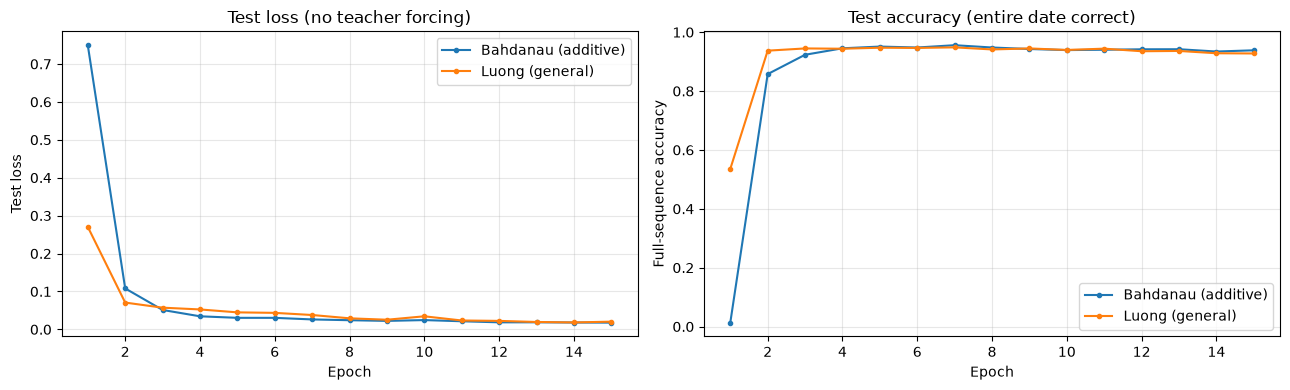

Variant                    Params   Final test loss   Final test acc
--------------------------------------------------------------------
Bahdanau (additive)       369,422            0.0178           0.9385
Luong (general)           334,350            0.0204           0.9277


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, history in histories.items():
    epochs = range(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs, history["test_loss"], marker="o", markersize=3, label=name)
    axes[1].plot(epochs, history["test_acc"], marker="o", markersize=3, label=name)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Test loss")
axes[0].set_title("Test loss (no teacher forcing)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Full-sequence accuracy")
axes[1].set_title("Test accuracy (entire date correct)")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

print(f"{'Variant':<22} {'Params':>10} {'Final test loss':>17} {'Final test acc':>16}")
print("-" * 68)
for name, history in histories.items():
    n_params = sum(p.numel() for p in models[name].parameters())
    print(
        f"{name:<22} {n_params:>10,} {history['test_loss'][-1]:>17.4f} "
        f"{history['test_acc'][-1]:>16.4f}"
    )

---
# Summary

### Core concepts
- The **bottleneck problem** in vanilla encoder-decoder: compressing all source info into a fixed-size vector fails for long sequences
- **Attention** solves this by letting the decoder access all encoder hidden states dynamically
- Every attention mechanism is **score → softmax → weighted sum**; variants differ only in the score function
- **Teacher forcing** accelerates training but creates exposure bias (model never sees its own errors during training). Scheduled sampling (decaying TF ratio) partially mitigates this.

### The evolutionary path
```
RNN (1990s)
  → LSTM/GRU (1997/2014) — solved vanishing gradients
    → Seq2Seq (2014) — encoder-decoder for sequence transduction  
      → Attention (2015) — solved the bottleneck problem
        → Transformer (2017) — removed the RNN entirely, using only attention
          → GPT, BERT, etc. — scaled Transformers to billions of parameters
```

**When to Still Use RNNs**:

Despite Transformers dominating most NLP benchmarks, RNNs remain relevant in specific scenarios:

1. **Extremely long sequences with limited memory**: RNNs process one token at a time with $O(1)$ memory per step, while Transformers need $O(n^2)$ for the attention matrix. State-space models (Mamba, S4) are the modern evolution of this idea.

2. **Streaming / online inference**: RNNs naturally process input incrementally. Transformers need the full sequence (or windowed approaches like Sliding Window Attention).

3. **Edge devices with limited compute**: Small LSTMs can be very efficient for tasks like keyword spotting or simple time-series prediction.

4. **Time-series with strong temporal structure**: Tasks where the sequential inductive bias of RNNs is genuinely helpful (e.g., control systems, some financial applications).

5. **As components within larger architectures**: RWKV and similar models combine RNN-like inference efficiency with Transformer-like training parallelism.